## Import library

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchinfo import summary

import pandas as pd
import os
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import copy

## Build Resnet 6

In [2]:
# Define the basic block for ResNet
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(BasicBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        # out = torch.add(out, self.shortcut(x))
        out += self.shortcut(x)
        return torch.relu(out)

# Define ResNet-6
class ResNet6(nn.Module):
    def __init__(self, num_classes=10):
        super(ResNet6, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)
        self.layer1 = self._make_layer(16, 16, 1, stride=2)
        self.layer2 = self._make_layer(16, 32, 1, stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(32, num_classes)

    def _make_layer(self, in_channels, out_channels, blocks, stride):
        layers = []
        layers.append(BasicBlock(in_channels, out_channels, stride))
        for _ in range(1, blocks):
            layers.append(BasicBlock(out_channels, out_channels, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.avgpool(out)
        out = torch.flatten(out, 1)
        out = self.fc(out)
        return out

## Set up the dataset and dataloader

In [5]:
# Set up the dataset and dataloaders
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=100, shuffle=False, num_workers=2)

100%|██████████| 170498071/170498071 [00:13<00:00, 12458243.69it/s]


Extracting ./data\cifar-10-python.tar.gz to ./data
Files already downloaded and verified


## Initialize the model, loss function, and optimizer

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ResNet6().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

## Training & Evaluation

In [8]:
# Training loop
def train(model, train_loader, criterion, optimizer, num_epochs=10):
    model.train()
    for epoch in range(num_epochs):
        total_loss = 0
        correct = 0
        total = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        accuracy = 100 * correct / total
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {total_loss/len(train_loader):.4f}, Accuracy: {accuracy:.2f}%")

In [9]:
def test(model, test_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    print(f"Test Accuracy: {100 * correct / total:.2f}%")

In [10]:
def test_first_images(model, test_loader, num_images=64):
    model.eval()
    correct = 0
    total = 0
    
    with torch.no_grad():
        count = 0
        for images, labels in test_loader:
            if count >= num_images:
                break
            remain = num_images - count
            if remain > 100:
                images, labels = images.to(device), labels.to(device)
            else:
                images, labels = images[:remain].to(device), labels[:remain].to(device)
            
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
            count = count + 100
            
        print(f"Total: {total}, Test Accuracy: {100 * correct / total:.2f}%")

In [18]:
# Run training and evaluation
# train(model, train_loader, criterion, optimizer, num_epochs=30)
test(model, test_loader)

Test Accuracy: 69.05%


In [12]:
# # Save the model
# # ***************************************************** # #
# # **************** don't run this part **************** # #
# # ***************************************************** # #

# model_path = 'resnet6.pth'
# torch.save(model.state_dict(), model_path)
# print(f"Quantized model saved to {model_path}")

## Model Analysis

In [13]:
model_path = 'resnet6.pth'
model.load_state_dict(torch.load(model_path, weights_only=True))

<All keys matched successfully>

In [14]:
summary(model, input_size=(64, 3, 32, 32), col_names=["input_size", "output_size", "num_params", "mult_adds"])

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Mult-Adds
ResNet6                                  [64, 3, 32, 32]           [64, 10]                  --                        --
├─Conv2d: 1-1                            [64, 3, 32, 32]           [64, 16, 16, 16]          432                       7,077,888
├─BatchNorm2d: 1-2                       [64, 16, 16, 16]          [64, 16, 16, 16]          32                        2,048
├─Sequential: 1-3                        [64, 16, 16, 16]          [64, 16, 8, 8]            --                        --
│    └─BasicBlock: 2-1                   [64, 16, 16, 16]          [64, 16, 8, 8]            --                        --
│    │    └─Conv2d: 3-1                  [64, 16, 16, 16]          [64, 16, 8, 8]            2,304                     9,437,184
│    │    └─BatchNorm2d: 3-2             [64, 16, 8, 8]            [64, 16, 8, 8]            32                        2,0

## Save Images and the Predicted Result

In [15]:
# Save the first 64 test images and their predictions
def save_predictions(model, test_loader, num_images=64):
    """
    Saves the first `num_images` test images as PNG + predictions in CSV.
    (Optional if you still need PNGs and CSV.)
    """
    os.makedirs("test_images", exist_ok=True)
    model.eval()
    image_list = []
    label_list = []
    confidence_list = []

    count = 0
    with torch.no_grad():
        for images, labels in test_loader:
            if count >= num_images:
                break
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            # probs = torch.nn.functional.softmax(outputs, dim=1)
            confidences, predictions = torch.max(outputs, 1)

            for i in range(images.shape[0]):
                if count >= num_images:
                    break
                image = images[i].cpu().permute(1, 2, 0).numpy()
                image = (image * 0.5 + 0.5) * 255  # Denormalize
                pil_img = Image.fromarray(image.astype('uint8'))
                pil_img.save(f"test_images/image_{count}.png")

                image_list.append(f"image_{count}.png")
                label_list.append(predictions[i].item())
                confidence_list.append(confidences[i].item())
                count += 1

    df = pd.DataFrame({
        "Predicted_Label": label_list,
        "Confidence": confidence_list
    })
    df.to_csv("predictions.csv", index=False, header=False)
    
# run save prediction
# save_predictions(model, test_loader, num_images=64)

In [16]:
def save_test_images_binary(dataset, num_images=64, out_dir="test_images_bin"):
    """
    Saves the first `num_images` test images in raw binary format.
    Each image is 32 x 32 x 3 = 3072 bytes (uint8).
    """
    os.makedirs(out_dir, exist_ok=True)

    for j in range(num_images):
        image, label = dataset[j]
        image = image.numpy()
        
        image = (image * 0.5 + 0.5) * 255
        image = np.round(image)
        image = image.astype(np.uint8)
            
        image.tofile(os.path.join(out_dir, f"image_{j}.bin"))
            
# run save image
# save_test_images_binary(test_dataset)


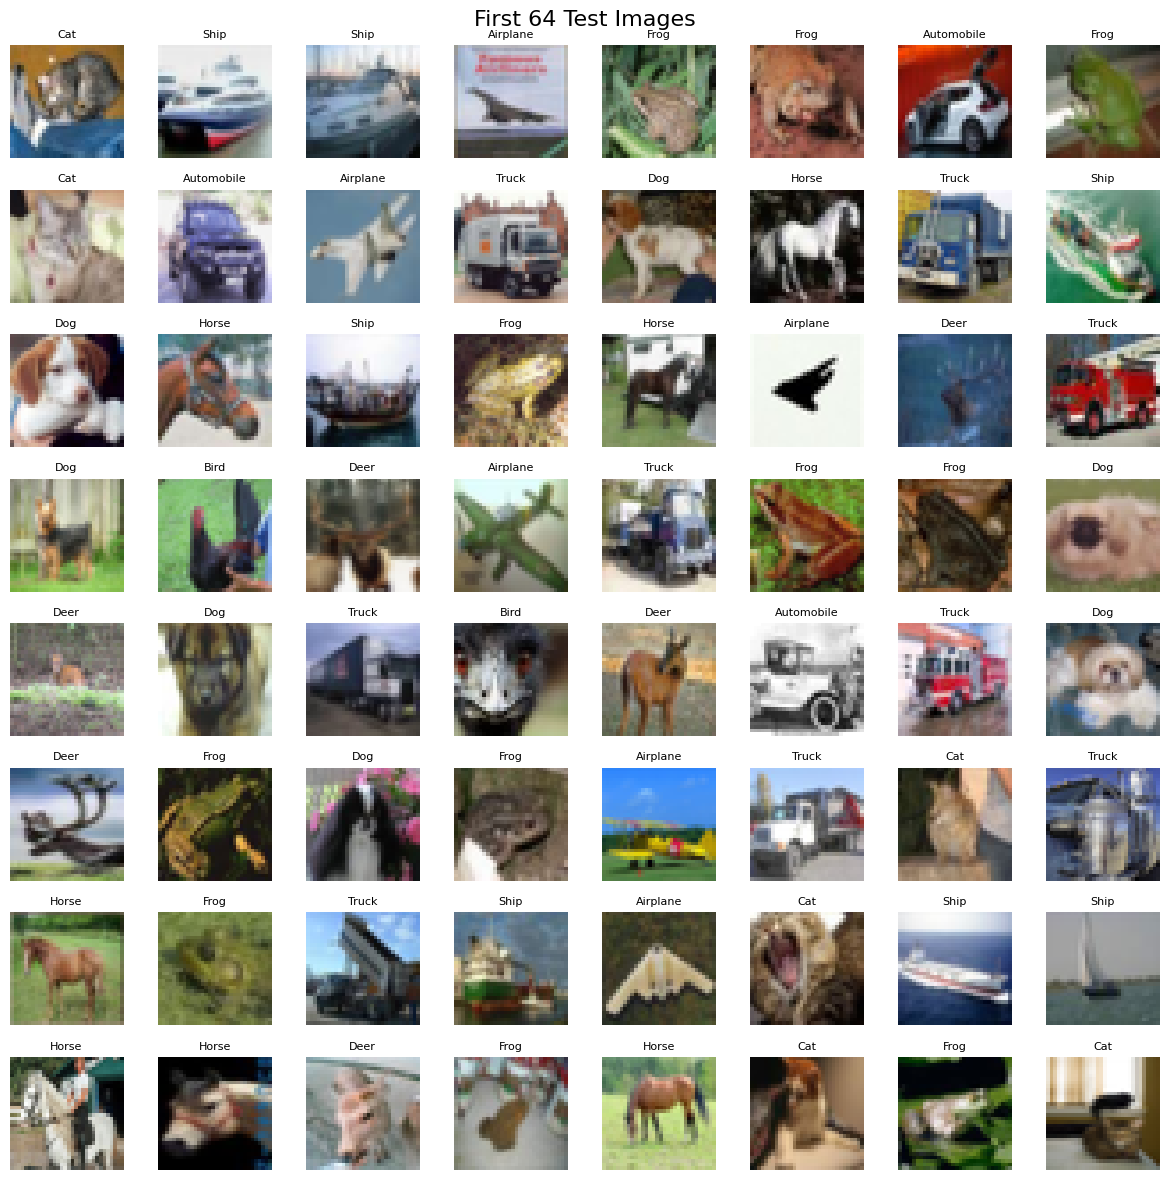

In [22]:
def show_test_images(dataset, num_images=64, grid_size=(8, 8)):
    """
    Displays the first `num_images` images from the test dataloader.
    `grid_size` determines the arrangement (rows, cols).
    """
    
    # CIFAR-10 label names
    cifar10_classes = [
        "Airplane", "Automobile", "Bird", "Cat", "Deer",
        "Dog", "Frog", "Horse", "Ship", "Truck"
    ]
    
    # Create figure and axes
    fig, axes = plt.subplots(grid_size[0], grid_size[1], figsize=(grid_size[1] * 1.5, grid_size[0] * 1.5))
    fig.suptitle("First 64 Test Images", fontsize=16)
    
    for j in range(num_images):
        image, label = dataset[j]
        image = image.permute(1, 2, 0).numpy()
        image = (image * 0.5 + 0.5) * 255
        image = np.round(image)
        image = image.astype(np.uint8)
        
        
        ax = axes.flat[j]
        ax.imshow(image)
        ax.set_title(cifar10_classes[label], fontsize=8)
        ax.axis("off")

    # Show plot
    plt.tight_layout()
    plt.subplots_adjust(top=0.95)  # Adjust title position
    plt.show()

# Call the function after defining the test_loader
show_test_images(test_dataset, num_images=64, grid_size=(8, 8))